# 03. Simulation-based evaluation

Because no independent reference of true pairs was available for this study, the comparison of procedural decisions used a
**synthetic reference**: synthetic death records are generated from sampled birth records with discrepancies
parameterized from the measured missingness of the real files and calibrated so that an earlier baseline reproduces its real
per-pass profile. True pairs are known by construction.

What it can show: differences between strategies under the generator's assumptions.
What it cannot show: accuracy on real pairs. The reference is not independent of the generator, the generator was calibrated
to the baseline and shares linkage keys with the procedure, 2014 is the training year, 2019 was used for calibration and for τ,
and one realization per scenario was run.

In [1]:
import json, glob, pandas as pd, numpy as np, matplotlib.pyplot as plt
S = "results/synthetic/"
rows = []
for yr in (2014, 2019, 2024):
    for tier in ("optimistic", "calibrated", "pessimistic"):
        a = json.load(open(f"{S}eval_v32_{yr}_{tier}.json")); b = json.load(open(f"{S}eval_v42_{yr}_{tier}_tau0.3.json"))
        rows.append(dict(year=yr, intensity=tier, baseline_P=a["precision"], baseline_R=a["recall_within_year"], baseline_F1=a["f1_within_year"],
                         procedure_P=b["precision"], procedure_R=b["recall_pairable"], procedure_F1=b["f1"]))
(pd.DataFrame(rows).set_index(["year", "intensity"]) * 100).round(1)

baseline_P  baseline_R  baseline_F1  procedure_P  \
year intensity                                                       
2014 optimistic         94.4        89.5         91.9         97.2   
     calibrated         91.7        86.6         89.1         96.4   
     pessimistic        85.9        80.3         83.0         94.8   
2019 optimistic         95.3        91.8         93.5         97.7   
     calibrated         92.6        88.9         90.7         97.2   
     pessimistic        87.2        83.3         85.2         95.8   
2024 optimistic         96.2        93.0         94.6         98.3   
     calibrated         93.7        90.3         92.0         97.8   
     pessimistic        88.1        84.7         86.4         96.5   

                  procedure_R  procedure_F1  
year intensity                               
2014 optimistic          92.4          94.7  
     calibrated          90.4          93.3  
     pessimistic         84.9          89.6  
2019 optimistic          94.6          96.1  
     calibrated          92.6          94.9  
     pessimistic         88.7          92.1  
2024 optimistic          95.7          96.9  
     calibrated          93.9          95.8  
     pessimistic         89.6          92.9

## Stepwise ablation (calibrated intensity)

Differences are conditional on the order of the changes.

In [2]:
ab = pd.concat([pd.read_csv(f"{S}taskA_ablation_{y}_calibrated.csv") for y in (2014, 2019, 2024)])
ab[["year", "step", "label", "matched", "wrong", "precision", "recall", "f1"]].assign(precision=lambda d: (d.precision * 100).round(1), recall=lambda d: (d.recall * 100).round(1), f1=lambda d: (d.f1 * 100).round(1))

,year,step,label,matched,wrong,precision,recall,f1
0,2014,0,v3.2: 4 greedy exact passes (current-year index),23902,1973,91.7,86.6,89.1
1,2014,1,Passes 1-3 only (mother's-age pass removed),21095,586,97.2,81.0,88.4
2,2014,2,+ cross-year index (previous-December births),21372,608,97.2,82.0,88.9
3,2014,3,+ tolerant unique-candidate recovery (greedy),21988,819,96.3,83.6,89.5
4,2014,4,"+ XGBoost scoring, greedy best-score 1:1 (tau ...",23748,850,96.4,90.4,93.3
5,2014,5,+ Hungarian optimal 1:1 (tau 0.3) = v4.2,23748,850,96.4,90.4,93.3
6,2014,S1,"suppl.: row 3 kept, then XGB greedy on remaini...",23938,1036,95.7,90.5,93.0
7,2014,S2,"suppl.: row 3 kept, then XGB Hungarian on rema...",23938,1036,95.7,90.5,93.0
8,2014,ref,reference v4.0 (P1-P4 cross-year + unique pass 5),24505,2201,91.0,88.1,89.5
0,2019,0,v3.2: 4 greedy exact passes (current-year index),22286,1649,92.6,88.9,90.7


## Fellegi-Sunter comparators

Three variants at probability thresholds from 0.01 to 0.99: current-year index only; with the previous-December index
(unsupervised); and with the procedure's source fields and m probabilities estimated from the true pairs of the 2014
reference. Thresholds were selected on the evaluation data and are exploratory.

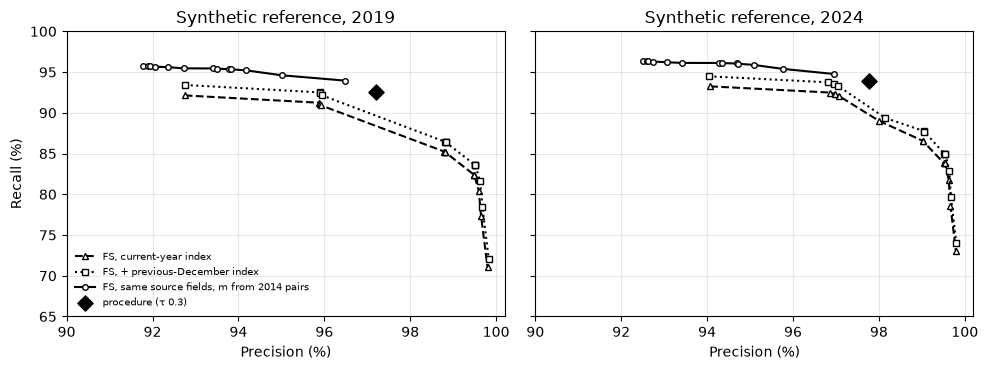

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, yr in zip(axes, (2019, 2024)):
    for f, lab, st in ((f"taskB_splink_sweep_{yr}_calibrated_seed42.csv", "FS, current-year index", "^--"),
                       (f"taskE_splink_xyear_{yr}_calibrated_seed42.csv", "FS, + previous-December index", "s:"),
                       (f"taskG_splink_sup_full_{yr}_calibrated_seed42.csv", "FS, same source fields, m from 2014 pairs", "o-")):
        d = pd.read_csv(S + f); d = d[d.assignment == "greedy"].sort_values("threshold")
        ax.plot(d.precision * 100, d.recall * 100, st, ms=4, label=lab, color="k", mfc="white")
    a = pd.read_csv(f"{S}taskA_ablation_{yr}_calibrated.csv"); p = a[a.step.astype(str) == "5"].iloc[0]
    ax.scatter(p.precision * 100, p.recall * 100, marker="D", s=60, c="k", label="procedure (τ 0.3)", zorder=5)
    ax.set_title(f"Synthetic reference, {yr}"); ax.set_xlabel("Precision (%)"); ax.set_xlim(90, 100.2); ax.set_ylim(65, 100); ax.grid(alpha=.3)
axes[0].set_ylabel("Recall (%)"); axes[0].legend(frameon=False, fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

In [4]:
for yr in (2019, 2024):
    d = pd.read_csv(f"{S}taskG_splink_sup_full_{yr}_calibrated_seed42.csv"); d = d[d.assignment == "greedy"]
    best = d.loc[d.f1.idxmax()]
    p = pd.read_csv(f"{S}taskA_ablation_{yr}_calibrated.csv"); p = p[p.step.astype(str) == "5"].iloc[0]
    print(yr, f"supervised FS best F1 {best.f1*100:.2f} (p >= {best.threshold}) vs procedure F1 {p.f1*100:.2f}; difference {100*(best.f1 - p.f1):+.2f} points")

2019 supervised FS best F1 95.20 (p >= 0.99) vs procedure F1 94.85; difference +0.35 points
2024 supervised FS best F1 95.85 (p >= 0.99) vs procedure F1 95.80; difference +0.05 points


In these simulated realizations, the supervised Fellegi-Sunter variant with the same source fields reached an F1 within
0.35 points above the procedure, so performance is not attributed to the classifier family. Assignment by the Hungarian
algorithm and greedy assignment by score selected the same pairs in 2014, 2019 and 2024 for τ from 0.1 to 0.9.